# Facial Expression Recognition: audit dataset dan baseline ResNet18

Mode default adalah audit-only: RUN_TRAINING=False, RESUME_RUN_DIR=None,
STAGE2_SCOPE=full_layer4, dan EXPERIMENT_VARIANT=combined. Pilih arsip
dataset yang sama di Google Drive, lalu gunakan Run all di Colab. Notebook
akan memeriksa gambar dan duplikat persis, mempertahankan split baseline,
menjalankan audit near duplicate train-validation, menyimpan laporan dalam
folder run baru, lalu melewati seluruh sel model dan training. Runtime CPU
cukup untuk audit; GPU T4 hanya diperlukan saat RUN_TRAINING=True.

Baseline combined full layer4 sebelumnya: validation accuracy 70,69%,
macro F1 68,41%, Fear F1 52,81%. Run last_block yang dilaporkan turun
menjadi accuracy sekitar 67,13% dan macro F1 63,78%. Output sel notebook
ini kosong; angka tersebut adalah hasil historis, bukan hasil audit baru.

Audit tidak mengubah arsip asli, label, atau keanggotaan split. Pembersihan
duplikat persis yang sudah menjadi bagian baseline tetap sama. Kandidat
near duplicate tidak dihapus. Test tidak dipakai untuk memilih model.

Dataset protocol switch: `DATASET_PROTOCOL='baseline'` preserves historical
membership. Opt in to `clean_grouped_v2` for a NEW benchmark; its scores are
not comparable to 70.69% on the historical validation set. Training remains
disabled. Read `DATASET_V2.md`. The module loader uses branch `salma`, an immutable
commit URL and a notebook-pinned SHA-256; it never falls back to `main`.


## 1. Library dan pemeriksaan PyTorch/torchvision

Colab menyediakan pasangan build PyTorch dan torchvision yang sesuai.
Sel ini memeriksa keduanya dengan mengimpor `torchvision.ops.nms`;
apabila gagal, pilih runtime Colab baru atau pasang pasangan versi resmi
yang cocok sebelum menjalankan notebook. Tidak memasang `torch` dan
`torchvision` secara terpisah demi menghindari mismatch binary.

In [56]:
import importlib.util
import subprocess
import sys

packages = {'sklearn': 'scikit-learn', 'pandas': 'pandas', 'numpy': 'numpy',
            'matplotlib': 'matplotlib', 'PIL': 'pillow', 'tqdm': 'tqdm'}
missing = [package for module, package in packages.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])

import hashlib
import json
import os
import random
import shutil
import time
import uuid
import warnings
import zipfile
from datetime import datetime, timezone
from pathlib import Path, PurePosixPath

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import PIL
from PIL import Image, ImageOps
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)
from tqdm.auto import tqdm
from IPython.display import display

try:
    import torch
    import torchvision
    from torch import nn
    from torch.utils.data import Dataset, DataLoader
    from torchvision import transforms
    from torchvision.models import resnet18, ResNet18_Weights
    from torchvision.ops import nms
    nms(torch.empty((0, 4)), torch.empty(0), 0.5)
except Exception as exc:
    raise RuntimeError('PyTorch/torchvision tidak kompatibel. Gunakan runtime '
                       'Colab baru atau pasang pasangan build resmi yang cocok.') from exc

assert hasattr(torch.amp, 'GradScaler'), 'PyTorch terlalu lama untuk API AMP notebook ini.'
print('PyTorch:', torch.__version__, 'torchvision:', torchvision.__version__)
print('CUDA available:', torch.cuda.is_available())

PyTorch: 2.11.0+cpu torchvision: 0.26.0+cpu
CUDA available: False


## 2. Google Drive dan konfigurasi mode

Untuk audit terpisah gunakan RUN_TRAINING=False dan RESUME_RUN_DIR=None.
Mode ini tidak memerlukan GPU, tidak memuat ResNet18 pretrained, tidak
membuat optimizer, tidak menjalankan epoch, dan tidak membuat checkpoint.
Folder hasil baru memakai nama audit_only serta timestamp dan UUID unik.

Saat eksperimen training berikutnya siap, ubah hanya RUN_TRAINING=True
dan pilih runtime Colab GPU T4. Default full_layer4 + combined tetap
konfigurasi baseline terbaik yang sudah teruji. Jangan menilai hasil audit
sebagai peningkatan performa model. Split dipastikan dengan SHA-256,
SPLIT_SEED=42, dan jumlah sampel baseline.

In [57]:
from google.colab import drive
drive.mount('/content/drive')

ZIP_PATH = Path('/content/drive/MyDrive/FacialExpression-Dataset/archive (1).zip')
OUTPUT_ROOT = Path('/content/drive/MyDrive/fer_cnn_outputs')
DATASET_PROTOCOL = 'clean_grouped_v2'  # Opt in explicitly: 'clean_grouped_v2'
assert DATASET_PROTOCOL in ('baseline', 'clean_grouped_v2')
V2_MODULE_SHA256 = '63e12c648a0fb3fd83a7a83d6e972009069ac0d9a4f1f42c39f54b7415030228'  # Verified module bytes for this notebook revision.
V2_LOCAL_MODULE_PATH = None  # Optional explicit upload path; same checksum required.
REVIEWED_V2_SPLIT_SHA256 = None  # Copy from reviewed audit summary before v2 training.
RUN_TRAINING = False  # False: audit-only Run all; True: train the verified full-layer4 baseline.
EXPERIMENT_VARIANT = 'combined'  # baseline, smoothing_only, photometric_only, combined
assert EXPERIMENT_VARIANT in ('baseline', 'smoothing_only', 'photometric_only', 'combined')
STAGE2_SCOPE = 'full_layer4'  # verified best scope; last_block remains an option
assert STAGE2_SCOPE in ('last_block', 'full_layer4')
EXPERIMENT_NAME = f'resnet18_{"train" if RUN_TRAINING else "audit_only"}_{STAGE2_SCOPE}_{EXPERIMENT_VARIANT}_v2'
if DATASET_PROTOCOL == 'clean_grouped_v2':
    EXPERIMENT_NAME = f'clean_grouped_v2_{EXPERIMENT_NAME}'
    assert EXPERIMENT_VARIANT == 'combined' and STAGE2_SCOPE == 'full_layer4'
RESUME_RUN_DIR = None  # Keep None for audit-only and for every new training experiment.
if not RUN_TRAINING and RESUME_RUN_DIR is not None:
    raise ValueError('Audit-only must create a new output directory; resume is disabled.')

if DATASET_PROTOCOL == 'clean_grouped_v2' and RESUME_RUN_DIR is not None:
    raise ValueError('V2 uses a fresh run directory; resume is not supported.')

SEED = 42  # Training and augmentation RNG.
SPLIT_SEED = 42  # Fixed membership across future training-seed replicates.
IMAGE_SIZE = 160
BATCH_SIZE = 64
NUM_WORKERS = 0
AUGMENT_DEGREES = 7
AUGMENT_TRANSLATE = 0.04
HEAD_DROPOUT = 0.3
WEIGHT_DECAY = 1e-4
STAGE2_WEIGHT_DECAY = 1e-3
STAGE2_LABEL_SMOOTHING = 0.05 if EXPERIMENT_VARIANT in ('smoothing_only', 'combined') else 0.0
STAGE2_PHOTOMETRIC = EXPERIMENT_VARIANT in ('photometric_only', 'combined')
PHOTOMETRIC_P = 0.5
BRIGHTNESS_JITTER = 0.12
CONTRAST_JITTER = 0.12
STAGE1_MAX_EPOCHS = 8
STAGE2_MAX_EPOCHS = 25
STAGE1_PATIENCE = 4
STAGE2_PATIENCE = 6
MIN_DELTA = 1e-4
SCHEDULER_PATIENCE = 2
SCHEDULER_FACTOR = 0.5
MIN_LR = 1e-6
STAGE1_HEAD_LR = 1e-3
STAGE2_LAYER4_LR = 1e-4
STAGE2_HEAD_LR = 5e-4
CLASS_FOLDERS = ['Angry', 'Fear', 'Happy', 'Sad', 'Suprise']
CLASS_NAMES = ['Angry', 'Fear', 'Happy', 'Sad', 'Surprise']
CLASS_TO_INDEX = {name: index for index, name in enumerate(CLASS_NAMES)}
FOLDER_TO_LABEL = dict(zip(CLASS_FOLDERS, CLASS_NAMES))
EXPECTED_ARCHIVE_SHA256 = '4524c810ef395c1a0ab237da31fa117b9aee3a71ebf42c3d1e7f006d8e62027f'
EXPECTED_SPLIT_SHA256 = '1ef54c784c90e488f83b1db34cf96358f0376a17f648cfdf6feb31e4125b0f1b'
EXPECTED_SPLIT_COUNTS = (20172, 4323, 4323)
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

assert ZIP_PATH.is_file(), f'ZIP not found: {ZIP_PATH}'
if RUN_TRAINING:
    assert torch.cuda.is_available(), 'Select a GPU (T4) runtime for training.'
DEVICE = torch.device('cuda' if RUN_TRAINING else 'cpu')
USE_AMP = RUN_TRAINING
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if RUN_TRAINING:
    torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True

experiment_root = OUTPUT_ROOT / EXPERIMENT_NAME
if RESUME_RUN_DIR is None:
    run_id = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ') + '_' + uuid.uuid4().hex[:8]
    RUN_DIR = experiment_root / run_id
    RUN_DIR.mkdir(parents=True, exist_ok=False)
else:
    RUN_DIR = Path(RESUME_RUN_DIR).resolve()
    assert RUN_DIR.is_dir() and RUN_DIR.parent == experiment_root.resolve(), 'Invalid ResNet18 resume directory.'
print('Run mode:', 'training' if RUN_TRAINING else 'audit-only')
print('Device:', torch.cuda.get_device_name(0) if RUN_TRAINING else 'CPU audit',
      'AMP:', USE_AMP)
print('Results folder:', RUN_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Run mode: audit-only
Device: CPU audit AMP: False
Results folder: /content/drive/MyDrive/fer_cnn_outputs/clean_grouped_v2_resnet18_audit_only_full_layer4_combined_v2/20261023T053244Z_db734cb4


## 3. Ekstrak ZIP ke penyimpanan lokal Colab
Hash SHA-256 mengidentifikasi isi ZIP untuk dokumentasi. Folder ekstraksi menggunakan hash tersebut,
sehingga file dari dataset berbeda tidak tercampur. Jalankan hingga progress bar selesai.

In [58]:
def hash_file(path):
    digest = hashlib.sha256()
    with open(path, 'rb') as handle:
        for block in iter(lambda: handle.read(8 * 1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()

archive_sha256 = hash_file(ZIP_PATH)
EXTRACT_DIR = Path('/content/fer_data') / archive_sha256[:16]
EXTRACT_DIR.mkdir(parents=True, exist_ok=True)
marker = EXTRACT_DIR / '.extraction_complete'
if not marker.exists():
    with zipfile.ZipFile(ZIP_PATH) as archive:
        entries = archive.infolist()
        required_bytes = sum(entry.file_size for entry in entries)
        assert shutil.disk_usage(EXTRACT_DIR).free > required_bytes + 1024**3, 'Not enough free runtime storage.'
        for entry in tqdm(entries, desc='Extracting'):
            relative = PurePosixPath(entry.filename)
            if relative.is_absolute() or '..' in relative.parts or '\\' in entry.filename:
                raise ValueError(f'Unsafe ZIP path: {entry.filename}')
            target = (EXTRACT_DIR / entry.filename).resolve()
            if not target.is_relative_to(EXTRACT_DIR.resolve()):
                raise ValueError(f'ZIP path outside destination: {entry.filename}')
            archive.extract(entry, EXTRACT_DIR)
    marker.write_text(archive_sha256)

candidates = [EXTRACT_DIR] + sorted(p for p in EXTRACT_DIR.rglob('Data') if p.is_dir())
candidates = [p for p in candidates if all((p / folder).is_dir() for folder in CLASS_FOLDERS)]
assert len(candidates) == 1, f'Expected one Data folder with {CLASS_FOLDERS}; found {candidates}'
DATA_DIR = candidates[0]
print('Data folder:', DATA_DIR)
print('ZIP SHA-256:', archive_sha256)


config = {
    'schema_version': 4,
    'run_training': RUN_TRAINING,
    'experiment_name': EXPERIMENT_NAME,
    'ablation_variant': EXPERIMENT_VARIANT,
    'run_id': RUN_DIR.name,
    'seed': SEED,
    'split_seed': SPLIT_SEED,
    'archive_sha256': archive_sha256,
    'split_ratios': [0.70, 0.15, 0.15],
    'split_sha256': None,
    'class_names': CLASS_NAMES,
    'folder_to_label': FOLDER_TO_LABEL,
    'model': {'name': 'ResNet18', 'weights': str(ResNet18_Weights.DEFAULT),
              'head_dropout': HEAD_DROPOUT, 'num_classes': len(CLASS_NAMES)},
    'input': {'channels': 3, 'size': IMAGE_SIZE, 'mean': list(IMAGENET_MEAN),
              'std': list(IMAGENET_STD), 'exif_transpose': True},
    'augmentation': {'horizontal_flip_p': 0.5, 'affine_degrees': AUGMENT_DEGREES,
                     'affine_translate': AUGMENT_TRANSLATE, 'interpolation': 'bilinear',
                     'fill': 128, 'stage2_photometric': STAGE2_PHOTOMETRIC,
                     'stage2_photometric_p': PHOTOMETRIC_P,
                     'brightness_jitter': BRIGHTNESS_JITTER,
                     'contrast_jitter': CONTRAST_JITTER},
    'batch_size': BATCH_SIZE,
    'num_workers': NUM_WORKERS,
    'loss': {'stage1': 'weighted_cross_entropy',
             'stage2': ('target_weighted_label_smoothing' if STAGE2_LABEL_SMOOTHING > 0
                        else 'weighted_cross_entropy'),
             'stage2_epsilon': STAGE2_LABEL_SMOOTHING,
             'class_weights': 'inverse_train_frequency',
             'reported_loss': 'unsmoothed_weighted_cross_entropy'},
    'optimizer': {'name': 'AdamW', 'stage1_weight_decay': WEIGHT_DECAY,
                  'stage2_weight_decay': STAGE2_WEIGHT_DECAY,
                  'stage1_head_lr': STAGE1_HEAD_LR,
                  'stage2_layer4_lr': STAGE2_LAYER4_LR,
                  'stage2_head_lr': STAGE2_HEAD_LR},
    'scheduler': {'name': 'ReduceLROnPlateau', 'monitor': 'validation_macro_f1',
                  'mode': 'max', 'factor': SCHEDULER_FACTOR,
                  'patience': SCHEDULER_PATIENCE, 'min_lr': MIN_LR,
                  'threshold': MIN_DELTA},
    'stage1': {'max_epochs': STAGE1_MAX_EPOCHS, 'early_stopping_patience': STAGE1_PATIENCE,
               'trainable': ['fc'], 'batch_norm': 'eval'},
    'stage2': {'max_epochs': STAGE2_MAX_EPOCHS, 'early_stopping_patience': STAGE2_PATIENCE,
               'scope': STAGE2_SCOPE,
               'trainable': (['layer4.1', 'fc'] if STAGE2_SCOPE == 'last_block'
                             else ['layer4', 'fc']), 'batch_norm': 'eval'},
    'amp': USE_AMP,
    'best_checkpoint_train_eval': True,
}
if DATASET_PROTOCOL == 'clean_grouped_v2':
    config['dataset_protocol'] = DATASET_PROTOCOL
versions = {'python': sys.version, 'torch': torch.__version__,
            'torchvision': torchvision.__version__, 'numpy': np.__version__,
            'pandas': pd.__version__, 'pillow': PIL.__version__,
            'sklearn': sklearn.__version__}
assert archive_sha256 == EXPECTED_ARCHIVE_SHA256, 'ZIP differs from SimpleCNN experiments.'
if RESUME_RUN_DIR is not None:
    saved_config = json.loads((RUN_DIR / 'config.json').read_text())
    saved_base = {key: value for key, value in saved_config.items() if key != 'split_sha256'}
    current_base = {key: value for key, value in config.items() if key != 'split_sha256'}
    if saved_base != current_base:
        raise ValueError('Resume rejected: configuration or archive differs.')

Data folder: /content/fer_data/4524c810ef395c1a/Data
ZIP SHA-256: 4524c810ef395c1a0ab237da31fa117b9aee3a71ebf42c3d1e7f006d8e62027f


## 4. Kualitas data dan duplikat persis sebelum split

Setiap gambar dibuka, orientasi EXIF diterapkan, lalu hash SHA-256 dihitung
dari ukuran dan piksel RGB. Gambar dengan piksel persis identik dicatat di
exact_duplicate_groups.csv; pasangan berlabel sama dan kelompok dengan
label berbeda dipisahkan. Alur baseline mempertahankan satu contoh dari
kelompok berlabel sama dan mengecualikan kelompok exact duplicate dengan
label bertentangan sebelum split. Arsip asli tidak diubah.

Duplikat persis berbeda dari near duplicate: perbedaan intensitas kecil
dapat menghasilkan hash SHA-256 berbeda. Audit near duplicate dilakukan
setelah split pada sel berikutnya, tanpa menghapus kandidat.

In [59]:
image_extensions = {'.png', '.jpg', '.jpeg', '.bmp', '.webp'}
paths = sorted(p for folder in CLASS_FOLDERS for p in (DATA_DIR / folder).rglob('*')
               if p.is_file() and p.suffix.lower() in image_extensions)
assert paths, 'No image files found.'
records, invalid = [], []
for path in tqdm(paths, desc='Checking images and exact duplicates'):
    folder = path.relative_to(DATA_DIR).parts[0]
    try:
        with warnings.catch_warnings():
            warnings.simplefilter('error', Image.DecompressionBombWarning)
            with Image.open(path) as original:
                original.load()
                original_width, original_height, mode = *original.size, original.mode
                image = ImageOps.exif_transpose(original).convert('RGB')
                digest = hashlib.sha256(str(image.size).encode() + b'|' + image.tobytes()).hexdigest()
        records.append({'path': path.relative_to(DATA_DIR).as_posix(),
                        'folder': folder,
                        'label': FOLDER_TO_LABEL[folder],
                        'width': original_width,
                        'height': original_height,
                        'mode': mode,
                        'pixel_sha256': digest})
    except Exception as error:
        invalid.append({'path': path.relative_to(DATA_DIR).as_posix(), 'error': str(error)})

manifest = pd.DataFrame(records)
assert len(manifest), 'No readable images remain.'
label_counts_per_hash = manifest.groupby('pixel_sha256')['label'].nunique()
conflict_hashes = set(label_counts_per_hash[label_counts_per_hash > 1].index)
conflicts = manifest[manifest.pixel_sha256.isin(conflict_hashes)].copy()
consistent = manifest[~manifest.pixel_sha256.isin(conflict_hashes)].copy()
clean = consistent.sort_values('path').drop_duplicates('pixel_sha256').reset_index(drop=True)
clean['target'] = clean.label.map(CLASS_TO_INDEX).astype(int)

# Reporting only: keep exact-duplicate categories separate from near-duplicate candidates.
exact_group_size = manifest.groupby('pixel_sha256')['path'].transform('size')
exact_label_count = manifest.groupby('pixel_sha256')['label'].transform('nunique')
exact_duplicate_rows = manifest.loc[exact_group_size > 1].copy()
exact_duplicate_rows['exact_group_size'] = exact_group_size[exact_group_size > 1].to_numpy()
exact_duplicate_rows['distinct_label_count'] = exact_label_count[exact_group_size > 1].to_numpy()
exact_duplicate_rows['audit_category'] = np.where(
    exact_duplicate_rows.distinct_label_count > 1,
    'exact_duplicate_conflicting_labels', 'exact_duplicate_same_label')
exact_duplicate_group_count = int((manifest.groupby('pixel_sha256').size() > 1).sum())

if RESUME_RUN_DIR is None:
    manifest.to_csv(RUN_DIR / 'audit_manifest.csv', index=False)
    pd.DataFrame(invalid, columns=['path', 'error']).to_csv(RUN_DIR / 'invalid_images.csv', index=False)
    conflicts.to_csv(RUN_DIR / 'conflicting_labels.csv', index=False)
    exact_duplicate_rows.to_csv(RUN_DIR / 'exact_duplicate_groups.csv', index=False)
    clean.to_csv(RUN_DIR / 'clean_manifest.csv', index=False)
audit_summary = {'input_images': len(paths), 'readable_images': len(manifest), 'invalid_images': len(invalid),
                 'conflicting_label_groups': len(conflict_hashes), 'conflicting_label_images': len(conflicts),
                 'same_label_duplicates_removed': len(consistent) - len(clean),
                 'exact_duplicate_groups': exact_duplicate_group_count,
                 'exact_duplicate_images': len(exact_duplicate_rows),
                 'retained_images': len(clean)}
if RESUME_RUN_DIR is None:
    (RUN_DIR / 'audit_summary.json').write_text(json.dumps(audit_summary, indent=2))
print(json.dumps(audit_summary, indent=2))

counts = pd.DataFrame({'original_readable': manifest.label.value_counts(),
                       'after_cleaning': clean.label.value_counts()}).reindex(CLASS_NAMES).fillna(0).astype(int)
display(counts)
assert (counts.after_cleaning >= 10).all(), 'Too few samples in one or more classes for stratified splitting.'


Checking images and exact duplicates:   0%|          | 0/59099 [00:00<?, ?it/s]

{
  "input_images": 59099,
  "readable_images": 59099,
  "invalid_images": 0,
  "conflicting_label_groups": 49,
  "conflicting_label_images": 262,
  "same_label_duplicates_removed": 30019,
  "exact_duplicate_groups": 27060,
  "exact_duplicate_images": 57292,
  "retained_images": 28818
}


,original_readable,after_cleaning
label,,
Angry,10148,4959
Fear,9732,4822
Happy,18439,9255
Sad,12553,6310
Surprise,8227,3472


## 5. Lihat contoh dan distribusi kelas
Judul gambar di bawah merupakan **label dari dataset**, bukan hasil prediksi.
Perhatikan apakah semua contoh benar-benar menunjukkan wajah dan apakah labelnya masuk akal.
Jika ada label meragukan, catat sebagai keterbatasan; pemeriksaan otomatis tidak menjamin semua label benar.

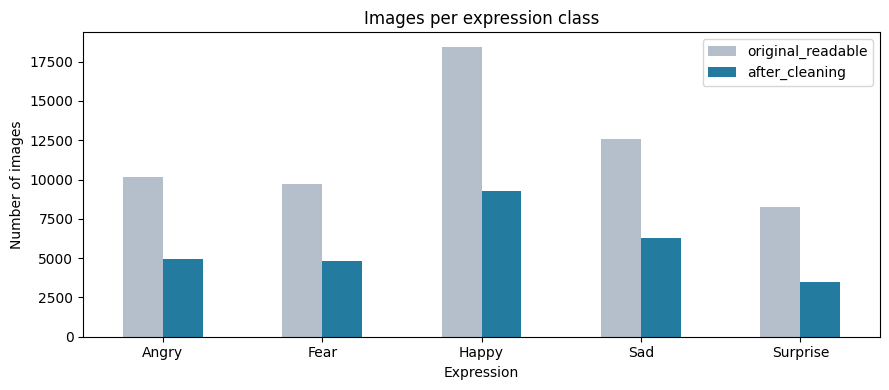

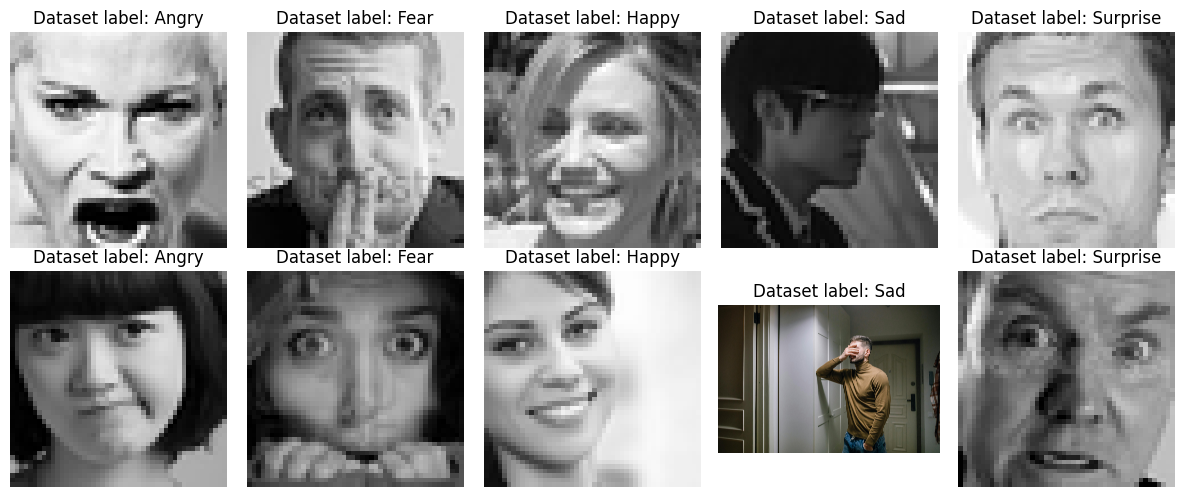

,image_size,width,height,image_count
0,48 x 48,48,48,57756
1,640 x 640,640,640,864
2,4000 x 6000,4000,6000,23
3,150 x 100,150,100,16
4,6000 x 4000,6000,4000,16
5,1600 x 1067,1600,1067,12
6,6720 x 4480,6720,4480,7
7,150 x 225,150,225,7
8,4480 x 6720,4480,6720,7
9,275 x 183,275,183,6


In [60]:
counts.plot(kind='bar', figsize=(9, 4), color=['#b5becb', '#247ba0'])
plt.title('Images per expression class')
plt.xlabel('Expression')
plt.ylabel('Number of images')
plt.xticks(rotation=0)
plt.tight_layout()
if RESUME_RUN_DIR is None:
    plt.savefig(RUN_DIR / 'class_distribution.png', dpi=150)
plt.show()

fig, axes = plt.subplots(2, len(CLASS_NAMES), figsize=(12, 5))
for column, label in enumerate(CLASS_NAMES):
    examples = clean[clean.label == label].sample(2, random_state=SEED)
    for row, (_, item) in enumerate(examples.iterrows()):
        with Image.open(DATA_DIR / item.path) as image:
            axes[row, column].imshow(ImageOps.exif_transpose(image).convert('RGB'))
        axes[row, column].set_title(f'Dataset label: {label}')
        axes[row, column].axis('off')
plt.tight_layout()
plt.show()
image_sizes = (
    manifest.groupby(['width', 'height'])
    .size()
    .reset_index(name='image_count')
    .sort_values('image_count', ascending=False)
    .head(10)
    .reset_index(drop=True)
)

image_sizes.insert(0, 'image_size', image_sizes['width'].astype(str) + ' x ' + image_sizes['height'].astype(str))
display(image_sizes)


## 5. Split identik dan audit kebocoran data

Lakukan pembagian stratified sama seperti baseline. Hash mencakup nama file,
label, hash piksel hasil decode, serta keanggotaan split; seed saja tidak
dianggap cukup. Duplikat piksel persis dibuang sebelum split dan dicek
lagi setelah split. Jika jumlah atau hash berubah, training berhenti.

For `clean_grouped_v2`, the following cell instead constructs components on
ALL readable images BEFORE split assignment. All candidate edges become
isolation constraints (not confirmed duplicates); strict RGB-confirmed edges
also receive separate reliable group IDs. Cross-label isolation components
are quarantined in the proposed manifests; no files or labels are changed.
Review counts and contact sheets before approving this new benchmark.


In [61]:
V2_TRAINING_APPROVED = False
if DATASET_PROTOCOL == 'baseline':
    train_df, remaining_df = train_test_split(
        clean,
        test_size=0.30,
        stratify=clean.target,
        random_state=SPLIT_SEED
    )

    val_df, test_df = train_test_split(
        remaining_df,
        test_size=0.50,
        stratify=remaining_df.target,
        random_state=SPLIT_SEED
    )

    train_df, val_df, test_df = (
        frame.reset_index(drop=True)
        for frame in (train_df, val_df, test_df)
    )

    split_manifest = pd.concat([
        train_df.assign(split='train'),
        val_df.assign(split='validation'),
        test_df.assign(split='test')
    ], ignore_index=True)

    assert split_manifest.path.is_unique
    assert split_manifest.pixel_sha256.is_unique
    assert len(split_manifest) == len(clean)
    assert set(train_df.target) == set(val_df.target) == set(test_df.target) == set(range(len(CLASS_NAMES)))


    display(
        pd.crosstab(
            split_manifest.label,
            split_manifest.split
        ).reindex(CLASS_NAMES)[['train', 'validation', 'test']]
    )

    print('No exact decoded-pixel duplicates cross the splits.')

    # Fingerprint exact membership and labels before resuming training.
    split_rows = split_manifest[['split', 'path', 'target', 'pixel_sha256']].sort_values(['split', 'path'])
    config['split_sha256'] = hashlib.sha256(split_rows.to_csv(index=False).encode('utf-8')).hexdigest()
    assert len(clean) == 28818 and (len(train_df), len(val_df), len(test_df)) == EXPECTED_SPLIT_COUNTS
    assert config['split_sha256'] == EXPECTED_SPLIT_SHA256, 'Split differs from SimpleCNN baseline.'
    config_path = RUN_DIR / 'config.json'
    if RESUME_RUN_DIR is None:
        config_path.write_text(json.dumps(config, indent=2))
        (RUN_DIR / 'environment_versions.json').write_text(json.dumps(versions, indent=2))
    else:
        assert config_path.is_file(), 'Missing config.json in resume directory.'
        saved_config = json.loads(config_path.read_text())
        if saved_config != config:
            raise ValueError('Resume rejected: training configuration or split differs from this run.')
    split_manifest.to_csv(RUN_DIR / 'split_manifest.csv', index=False)
    print('Split SHA-256:', config['split_sha256'])
else:
    # Colab opening a GitHub notebook does not supply sibling Python files.
    # Resolve salma once, then fetch immutable commit contents; never use main.
    import importlib.util
    import re
    import tempfile
    from urllib.request import Request, urlopen

    def load_v2_module(expected_sha256, local_path=None):
        repository = 'salmakamila126/facial-expression-recognition-cnn-pytorch'
        branch = 'salma'
        if not re.fullmatch(r'[0-9a-f]{64}', expected_sha256):
            raise ValueError('Invalid expected v2 module SHA-256')
        if local_path is not None:
            source_path = Path(local_path).resolve()
            payload = source_path.read_bytes()
            provenance = {'source': 'explicit_local_upload', 'path': str(source_path)}
        else:
            try:
                request = Request(
                    f'https://api.github.com/repos/{repository}/commits/{branch}',
                    headers={'Accept': 'application/vnd.github+json', 'User-Agent': 'fer-v2-audit'})
                with urlopen(request, timeout=30) as response:
                    commit = json.load(response)['sha']
                if not re.fullmatch(r'[0-9a-f]{40}', commit):
                    raise ValueError('Invalid commit returned by GitHub')
                url = f'https://raw.githubusercontent.com/{repository}/{commit}/clean_grouped_v2.py'
                with urlopen(Request(url, headers={'User-Agent': 'fer-v2-audit'}), timeout=30) as response:
                    payload = response.read(1024 * 1024 + 1)
                provenance = {'source': 'github', 'repository': repository,
                              'branch': branch, 'commit': commit, 'url': url}
            except Exception as error:
                raise RuntimeError(
                    'Cannot fetch v2 from branch salma. Ensure this notebook and matching '
                    'clean_grouped_v2.py are available on salma, or upload the matching module '
                    'and set V2_LOCAL_MODULE_PATH. No fallback to main is permitted.') from error
        if len(payload) > 1024 * 1024 or hashlib.sha256(payload).hexdigest() != expected_sha256:
            raise ValueError('V2 module checksum mismatch; use the matching notebook/module revision.')
        # Unique runtime file, explicit spec: ignore stale imports or same-name cwd modules.
        with tempfile.NamedTemporaryFile(prefix='fer_v2_', suffix='.py', delete=False) as handle:
            handle.write(payload)
            verified_path = Path(handle.name)
        spec = importlib.util.spec_from_file_location('fer_verified_clean_grouped_v2', verified_path)
        module = importlib.util.module_from_spec(spec)
        spec.loader.exec_module(module)
        provenance['sha256'] = expected_sha256
        return module, provenance

    v2_module, v2_module_source = load_v2_module(V2_MODULE_SHA256, V2_LOCAL_MODULE_PATH)
    prepare = v2_module.prepare
    (RUN_DIR / 'v2_module_source.json').write_text(json.dumps(v2_module_source, indent=2))
    print('Verified v2 module:', v2_module_source)
    split_manifest, v2_summary = prepare(
        manifest, DATA_DIR, RUN_DIR / 'clean_grouped_v2',
        seed=SPLIT_SEED, archive_sha256=archive_sha256)
    train_df, val_df, test_df = (
        split_manifest[split_manifest.split == name].reset_index(drop=True)
        for name in ('train', 'validation', 'test'))
    clean = split_manifest.drop(columns='split').copy()
    config['split_sha256'] = v2_summary['split_sha256']
    config['dataset_v2'] = v2_summary
    (RUN_DIR / 'config.json').write_text(json.dumps(config, indent=2))
    (RUN_DIR / 'environment_versions.json').write_text(json.dumps(versions, indent=2))
    print(json.dumps(v2_summary, indent=2))
    display(pd.read_csv(RUN_DIR / 'clean_grouped_v2' / 'class_distribution.csv'))
    display(pd.read_csv(RUN_DIR / 'clean_grouped_v2' / 'split_distribution.csv'))
    display(pd.read_csv(RUN_DIR / 'clean_grouped_v2' / 'groups.csv').query('manual_review'))
    if RUN_TRAINING and REVIEWED_V2_SPLIT_SHA256 != config['split_sha256']:
        raise ValueError('Review the audit, decisions, thresholds and contact sheets first; '
                         'set REVIEWED_V2_SPLIT_SHA256 to the approved split hash.')

    V2_TRAINING_APPROVED = (REVIEWED_V2_SPLIT_SHA256 == config['split_sha256'])


Verified v2 module: {'source': 'github', 'repository': 'salmakamila126/facial-expression-recognition-cnn-pytorch', 'branch': 'salma', 'commit': '709829ea20a5dc08814e451af30b34b1015c9568', 'url': 'https://raw.githubusercontent.com/salmakamila126/facial-expression-recognition-cnn-pytorch/709829ea20a5dc08814e451af30b34b1015c9568/clean_grouped_v2.py', 'sha256': '63e12c648a0fb3fd83a7a83d6e972009069ac0d9a4f1f42c39f54b7415030228'}
{
  "protocol": "clean_grouped_v2",
  "archive_sha256": "4524c810ef395c1a0ab237da31fa117b9aee3a71ebf42c3d1e7f006d8e62027f",
  "config_sha256": "79febcdbdf5abaadb34392dbf839fe8294638da5991f4e4759ae33160636d8f2",
  "dataset_sha256": "970c3ad00dbd4d451c19322983fc88a91eb84d65e962766c88d768dfff269283",
  "split_sha256": "7e9742da12ed2caa4652e23af7a78215f57fd1e44e37cec2e7c70cd664b66ec8",
  "readable_images": 59099,
  "retained_images": 28775,
  "candidate_pairs": 160,
  "high_confidence_pairs": 45,
  "isolation_groups": 28735,
  "multi_image_groups": 27011,
  "reliable_gr

,label,original_readable,proposed_retained,quarantine_label_conflict,redundant_exact_copy,quarantine_fraction
0,Angry,10148,4947,101,5100,0.009953
1,Fear,9732,4807,114,4811,0.011714
2,Happy,18439,9254,11,9174,0.000597
3,Sad,12553,6301,72,6180,0.005736
4,Surprise,8227,3466,75,4686,0.009116


,label,train,validation,test
0,Angry,3463,742,742
1,Fear,3365,721,721
2,Happy,6478,1388,1388
3,Sad,4411,945,945
4,Surprise,2426,520,520


,group_id,images,labels,reliable_groups,manual_review
0,isolate_00072eaec3d007a44ecfa3b7dfb9685a65b021...,2,Happy,1,True
2,isolate_000a4a680904600cf75d9b1d9338c68d217556...,2,Angry,1,True
3,isolate_000c82a69f88e4f782a9feee933b5f802b2fcd...,2,Fear,1,True
4,isolate_000cd072e3ace69caabf98a948717b97d5a01e...,2,Happy,1,True
5,isolate_000f93f87ccfe2af3001ea3c4bbb98cf058bdb...,2,Angry,2,True
...,...,...,...,...,...
28728,isolate_fff659f110883833b773f86534a02984460857...,2,Sad,1,True
28729,isolate_fff7b9e9994bebee3366e04bf6b4d44f54c28b...,4,Fear,1,True
28730,isolate_fffa69c53af1d38b73fad17bd148c5a9c7b60a...,2,Sad,1,True
28732,isolate_fffe78b02fd051ca5184512f7ed2e5923af1c7...,2,Surprise,1,True


## 5b. Kandidat near duplicate train-validation

Audit ini memeriksa train dan validation yang sudah dibersihkan, tanpa
memakai test untuk memilih atau memperbaiki model. Gambar diubah menjadi
grayscale, dHash 64-bit dihitung dari ukuran 9x8, kemudian kandidat dengan
jarak Hamming <=4 diperiksa ulang memakai rerata beda piksel (MAE) <=3
pada ukuran 48x48. Lima blok hash menjamin semua pasangan dengan jarak
Hamming <=4 dipertimbangkan oleh pencarian kandidat.

CSV utama memuat semua kandidat; CSV terpisah memuat pasangan lintas label
dan pasangan yang melibatkan Fear, Sad, Angry, atau Surprise. Contact sheet
menampilkan pasangan prioritas untuk pemeriksaan manual. Konflik label
merupakan dugaan inkonsistensi, bukan vonis label salah atau leakage yang
sudah terkonfirmasi. Wajah yang berbeda namun mirip dapat menjadi false
positive; crop, pergeseran, perubahan warna, atau kompresi kuat dapat
menjadi false negative. Tidak ada kandidat yang dihapus atau dipindah.

In [62]:
if DATASET_PROTOCOL == 'baseline':
    from collections import defaultdict

    def audit_gray_and_dhash(relative_path):
        with Image.open(DATA_DIR / relative_path) as original:
            gray = ImageOps.exif_transpose(original).convert('L')
            hash_pixels = np.asarray(
                gray.resize((9, 8), Image.Resampling.BILINEAR), dtype=np.uint8)
            comparison_pixels = np.asarray(
                gray.resize((48, 48), Image.Resampling.BILINEAR), dtype=np.uint8)
        bits = (hash_pixels[:, 1:] > hash_pixels[:, :-1]).ravel()
        dhash = int.from_bytes(np.packbits(bits).tobytes(), 'big')
        return dhash, comparison_pixels

    audit_train = train_df[['path', 'label']].to_dict('records')
    audit_validation = val_df[['path', 'label']].to_dict('records')
    train_hashes, train_pixels = [], []
    # Five disjoint blocks ensure at least one exact block match for Hamming <=4.
    HASH_BLOCKS = ((0, 13), (13, 13), (26, 13), (39, 13), (52, 12))
    train_buckets = defaultdict(list)
    for index, item in enumerate(tqdm(audit_train, desc='Near-duplicate audit: train')):
        dhash, pixels = audit_gray_and_dhash(item['path'])
        train_hashes.append(dhash)
        train_pixels.append(pixels)
        for block, (shift, width) in enumerate(HASH_BLOCKS):
            train_buckets[(block, (dhash >> shift) & ((1 << width) - 1))].append(index)

    near_duplicate_rows = []
    for item in tqdm(audit_validation, desc='Near-duplicate audit: validation'):
        val_hash, val_pixels = audit_gray_and_dhash(item['path'])
        candidate_indices = set()
        for block, (shift, width) in enumerate(HASH_BLOCKS):
            candidate_indices.update(
                train_buckets[(block, (val_hash >> shift) & ((1 << width) - 1))])
        for index in candidate_indices:
            distance = (train_hashes[index] ^ val_hash).bit_count()
            if distance > 4:
                continue
            pixel_mae = float(np.abs(train_pixels[index].astype(np.int16) -
                                     val_pixels.astype(np.int16)).mean())
            if pixel_mae <= 3.0:
                train_item = audit_train[index]
                near_duplicate_rows.append({
                    'train_path': train_item['path'],
                    'train_label': train_item['label'],
                    'validation_path': item['path'],
                    'validation_label': item['label'],
                    'dhash_hamming': distance,
                    'pixel_mae_48x48': pixel_mae,
                    'label_conflict': train_item['label'] != item['label'],
                })

    near_duplicate_columns = [
        'train_path', 'train_label', 'validation_path', 'validation_label',
        'dhash_hamming', 'pixel_mae_48x48', 'label_conflict']
    near_duplicate_df = pd.DataFrame(near_duplicate_rows, columns=near_duplicate_columns)
    focus_classes = {'Fear', 'Sad', 'Angry', 'Surprise'}
    near_duplicate_df['focus_class_pair'] = (
        near_duplicate_df.train_label.isin(focus_classes) |
        near_duplicate_df.validation_label.isin(focus_classes))
    near_duplicate_df['audit_category'] = np.where(
        near_duplicate_df.label_conflict,
        'near_duplicate_cross_label_candidate',
        'near_duplicate_same_label_candidate')
    near_duplicate_df.sort_values(
        ['label_conflict', 'focus_class_pair', 'pixel_mae_48x48', 'dhash_hamming'],
        ascending=[False, False, True, True], inplace=True)
    cross_label_candidates = near_duplicate_df[near_duplicate_df.label_conflict].copy()
    focus_candidates = near_duplicate_df[near_duplicate_df.focus_class_pair].copy()
    near_duplicate_df.to_csv(
        RUN_DIR / 'train_validation_near_duplicate_candidates.csv', index=False)
    cross_label_candidates.to_csv(
        RUN_DIR / 'train_validation_cross_label_candidates.csv', index=False)
    focus_candidates.to_csv(
        RUN_DIR / 'train_validation_focus_candidates.csv', index=False)
    pair_summary = (near_duplicate_df.groupby(
        ['train_label', 'validation_label', 'audit_category']).size()
        .rename('candidate_pairs').reset_index())
    pair_summary.sort_values('candidate_pairs', ascending=False, inplace=True)
    pair_summary.to_csv(RUN_DIR / 'near_duplicate_label_pair_summary.csv', index=False)

    audit_counts = {
        'run_mode': 'training' if RUN_TRAINING else 'audit-only',
        'exact_duplicate_method': 'SHA-256 of decoded RGB pixels and dimensions after EXIF transpose',
        'near_duplicate_method': '64-bit dHash, then grayscale 48x48 pixel MAE',
        'dhash_hamming_threshold': 4,
        'pixel_mae_threshold': 3.0,
        'train_validation_candidate_pairs': len(near_duplicate_df),
        'same_label_candidate_pairs': len(near_duplicate_df) - len(cross_label_candidates),
        'cross_label_candidate_pairs': len(cross_label_candidates),
        'focus_candidate_pairs': len(focus_candidates),
        'focus_cross_label_candidate_pairs': int(
            focus_candidates.label_conflict.sum()),
        'unique_train_images_flagged': int(near_duplicate_df.train_path.nunique()),
        'unique_validation_images_flagged': int(
            near_duplicate_df.validation_path.nunique()),
        'split_modified': False,
        'near_duplicate_images_removed': 0,
        'test_images_scanned_for_near_duplicates': False,
        'test_used_for_model_selection': False,
        'candidates_confirmed_by_manual_review': False,
    }
    (RUN_DIR / 'near_duplicate_audit_summary.json').write_text(
        json.dumps(audit_counts, indent=2))
    print(json.dumps(audit_counts, indent=2))
    display(pair_summary)
    display(cross_label_candidates.head(20))
    display(focus_candidates.head(20))

    def save_pair_contact_sheet(frame, filename, title, max_pairs=12):
        selected = frame.head(max_pairs)
        if selected.empty:
            return
        fig, axes = plt.subplots(len(selected), 2,
                                 figsize=(8, 2.8 * len(selected)), squeeze=False)
        for row_number, (_, pair) in enumerate(selected.iterrows()):
            for column, (split, path, label) in enumerate((
                ('train', pair.train_path, pair.train_label),
                ('validation', pair.validation_path, pair.validation_label))):
                with Image.open(DATA_DIR / path) as original:
                    image = ImageOps.exif_transpose(original).convert('RGB')
                    axes[row_number, column].imshow(image)
                axes[row_number, column].set_title(
                    f'{split}: {label} / {path}', fontsize=9)
                axes[row_number, column].axis('off')
            axes[row_number, 0].set_ylabel(
                f'dHash {pair.dhash_hamming}; MAE {pair.pixel_mae_48x48:.2f}',
                fontsize=8)
        fig.suptitle(title, fontsize=12)
        plt.tight_layout()
        plt.savefig(RUN_DIR / filename, dpi=150)
        plt.show()
        plt.close(fig)

    save_pair_contact_sheet(
        cross_label_candidates,
        'train_validation_cross_label_contact_sheet.png',
        'Cross-label near-duplicate candidates (manual review required)')
    save_pair_contact_sheet(
        focus_candidates[~focus_candidates.label_conflict],
        'train_validation_focus_same_label_contact_sheet.png',
        'Fear / Sad / Angry / Surprise same-label candidates')

    report_lines = [
        '# Dataset quality audit',
        '',
        f'Run directory: {RUN_DIR}',
        f'Run mode: {"training" if RUN_TRAINING else "audit-only"}',
        f'Archive SHA-256: {archive_sha256}',
        f'Split SHA-256: {config["split_sha256"]}',
        '',
        '## Categories',
        'Exact duplicate: dimensions and decoded RGB bytes match after EXIF correction; '
        'see exact_duplicate_groups.csv. Existing baseline cleaning of exact matches is unchanged.',
        'Near-duplicate candidate: train-validation pair with 64-bit dHash Hamming '
        'distance <=4 and grayscale 48x48 pixel MAE <=3. '
        'See train_validation_near_duplicate_candidates.csv.',
        'Suspected label inconsistency: near-duplicate candidate whose dataset '
        'labels differ. This is a review flag, not a confirmed annotation error; '
        'see train_validation_cross_label_candidates.csv.',
        '',
        '## Counts',
        f'Exact duplicate groups: {audit_summary["exact_duplicate_groups"]}',
        f'Exact duplicate images: {audit_summary["exact_duplicate_images"]}',
        f'Exact conflicting-label groups: {audit_summary["conflicting_label_groups"]}',
        f'Near-duplicate train-validation candidate pairs: {len(near_duplicate_df)}',
        f'Cross-label near-duplicate candidate pairs: {len(cross_label_candidates)}',
        f'Focus-class candidate pairs: {len(focus_candidates)}',
        '',
        '## Interpretation and limitations',
        'dHash and pixel MAE are screening rules. Visually similar faces can be '
        'false positives; crop, alignment, color, and compression changes can be '
        'false negatives. Review the paired images before any conclusion.',
        'No near-duplicate was removed or relabeled. The original files, labels, '
        'and train/validation/test membership were not changed by this audit.',
        'Only train and validation images were scanned for near duplicates. '
        'Test information is not used to select or change the model.',
        '',
        '## Priority review files',
        '1. train_validation_cross_label_candidates.csv and '
        'train_validation_cross_label_contact_sheet.png',
        '2. train_validation_focus_candidates.csv and '
        'train_validation_focus_same_label_contact_sheet.png',
        '3. train_validation_near_duplicate_candidates.csv and '
        'near_duplicate_label_pair_summary.csv',
        '4. exact_duplicate_groups.csv, conflicting_labels.csv, and audit_summary.json',
    ]
    (RUN_DIR / 'dataset_audit_report.md').write_text(
        '\n'.join(report_lines) + '\n', encoding='utf-8')
    if not RUN_TRAINING:
        print('Audit-only complete. All downstream model and training cells are disabled.')

else:
    near_duplicate_df = pd.DataFrame(columns=['validation_path'])
    print('V2 pre-split audit saved in', RUN_DIR / 'clean_grouped_v2')


V2 pre-split audit saved in /content/drive/MyDrive/fer_cnn_outputs/clean_grouped_v2_resnet18_audit_only_full_layer4_combined_v2/20261023T053244Z_db734cb4/clean_grouped_v2


## 6. Transform RGB dan DataLoader (hanya saat RUN_TRAINING=True)

Sel ini dan semua sel model, training, evaluasi, serta ekspor training
berikutnya dilewati ketika RUN_TRAINING=False. Dalam mode training,
transform dan DataLoader baseline tetap sama: augmentation hanya untuk
train; validation dan test memakai transform deterministik.

In [63]:
if RUN_TRAINING and DATASET_PROTOCOL == 'clean_grouped_v2':
    if not globals().get('V2_TRAINING_APPROVED', False):
        raise RuntimeError('V2 training blocked: run and approve the split audit first.')
    if REVIEWED_V2_SPLIT_SHA256 != config['split_sha256']:
        raise RuntimeError('V2 training blocked: reviewed split hash does not match.')

if RUN_TRAINING:
    base_train_steps = [
        transforms.Resize((IMAGE_SIZE, IMAGE_SIZE), interpolation=transforms.InterpolationMode.BILINEAR),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomAffine(degrees=AUGMENT_DEGREES,
                                translate=(AUGMENT_TRANSLATE, AUGMENT_TRANSLATE),
                                interpolation=transforms.InterpolationMode.BILINEAR,
                                fill=(128, 128, 128)),
    ]
    tensor_steps = [transforms.ToTensor(), transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)]
    train_transform = transforms.Compose(base_train_steps + tensor_steps)
    if STAGE2_PHOTOMETRIC:
        photometric_step = transforms.RandomApply(
            [transforms.ColorJitter(brightness=BRIGHTNESS_JITTER, contrast=CONTRAST_JITTER)],
            p=PHOTOMETRIC_P)
        stage2_train_transform = transforms.Compose(base_train_steps + [photometric_step] + tensor_steps)
    else:
        stage2_train_transform = train_transform
    eval_transform = transforms.Compose([
        transforms.Resize((IMAGE_SIZE, IMAGE_SIZE), interpolation=transforms.InterpolationMode.BILINEAR),
        transforms.ToTensor(),
        transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    ])

    class FaceDataset(Dataset):
        def __init__(self, frame, root, transform):
            self.frame = frame.reset_index(drop=True)
            self.root, self.transform = Path(root), transform

        def __len__(self):
            return len(self.frame)

        def __getitem__(self, index):
            item = self.frame.iloc[index]
            with Image.open(self.root / item.path) as image:
                rgb = ImageOps.exif_transpose(image).convert('RGB')
                tensor = self.transform(rgb)
            return tensor, int(item.target)

    def seed_worker(worker_id):
        worker_seed = torch.initial_seed() % 2**32
        random.seed(worker_seed)
        np.random.seed(worker_seed)

    def make_loaders():
        generator = torch.Generator().manual_seed(SEED)
        options = dict(batch_size=BATCH_SIZE, num_workers=NUM_WORKERS,
                       pin_memory=True, worker_init_fn=seed_worker)
        train = DataLoader(FaceDataset(train_df, DATA_DIR, train_transform),
                           shuffle=True, generator=generator, **options)
        validation = DataLoader(FaceDataset(val_df, DATA_DIR, eval_transform),
                                shuffle=False, **options)
        test = DataLoader(FaceDataset(test_df, DATA_DIR, eval_transform),
                          shuffle=False, **options)
        return train, validation, test

    train_loader, val_loader, test_loader = make_loaders()
    images, labels = next(iter(val_loader))
    assert images.shape == (BATCH_SIZE, 3, IMAGE_SIZE, IMAGE_SIZE)
    assert labels.shape == (BATCH_SIZE,)
    print('Input batch:', tuple(images.shape), 'labels:', tuple(labels.shape))

## 7. Pretrained ResNet18 dan classifier lima kelas

`ResNet18_Weights.DEFAULT` memuat bobot ImageNet. Fully connected head
diganti menjadi dropout 0,3 dan linear lima keluaran. Uji forward berikut
memakai tensor sintetis tanpa training untuk memastikan shape output.

In [64]:
if RUN_TRAINING and DATASET_PROTOCOL == 'clean_grouped_v2':
    if not globals().get('V2_TRAINING_APPROVED', False):
        raise RuntimeError('V2 training blocked: run and approve the split audit first.')
    if REVIEWED_V2_SPLIT_SHA256 != config['split_sha256']:
        raise RuntimeError('V2 training blocked: reviewed split hash does not match.')

if RUN_TRAINING:
    pretrained_weights = ResNet18_Weights.DEFAULT
    model = resnet18(weights=pretrained_weights)
    in_features = model.fc.in_features
    assert in_features == 512, 'Unexpected ResNet18 classifier input width.'
    model.fc = nn.Sequential(nn.Dropout(HEAD_DROPOUT), nn.Linear(in_features, len(CLASS_NAMES)))
    model = model.to(DEVICE)
    model.eval()
    with torch.inference_mode():
        sample_logits = model(torch.zeros(2, 3, IMAGE_SIZE, IMAGE_SIZE, device=DEVICE))
    assert sample_logits.shape == (2, len(CLASS_NAMES))
    assert model.fc[-1].out_features == 5
    print('Pretrained weights:', pretrained_weights)
    print('Classifier outputs:', model.fc[-1].out_features)
    print('Model output shape:', tuple(sample_logits.shape))

## 8. Loss, cakupan fine-tuning, BatchNorm, dan AMP

Bobot kelas berasal hanya dari train. Stage 1 memakai weighted
cross-entropy dan melatih head. Stage 2 combined memakai target-weighted
label smoothing epsilon 0,05 dan photometric jitter. Kolom loss tetap
weighted cross-entropy tanpa smoothing untuk perbandingan antar-run;
objective_loss adalah fungsi yang dioptimalkan.

Stage 2 default kembali melatih seluruh layer4, termasuk blok transisi
layer4.0, dan head (8.396.293 parameter). Opsi last_block tetap tersedia
untuk reproduksi ablation negatif. Semua BatchNorm memakai mode eval:
running statistics tidak diperbarui, tetapi parameter affine pada blok
yang dibuka tetap trainable. AMP float16 dan GradScaler aktif di GPU T4.
Validation selalu dalam mode eval.

In [65]:
if RUN_TRAINING and DATASET_PROTOCOL == 'clean_grouped_v2':
    if not globals().get('V2_TRAINING_APPROVED', False):
        raise RuntimeError('V2 training blocked: run and approve the split audit first.')
    if REVIEWED_V2_SPLIT_SHA256 != config['split_sha256']:
        raise RuntimeError('V2 training blocked: reviewed split hash does not match.')

if RUN_TRAINING:
    train_counts = np.bincount(train_df.target.to_numpy(), minlength=len(CLASS_NAMES))
    assert len(train_counts) == len(CLASS_NAMES) and (train_counts > 0).all()
    class_weights = len(train_df) / (len(CLASS_NAMES) * train_counts)
    class_weight_tensor = torch.tensor(class_weights, dtype=torch.float32, device=DEVICE)
    reference_criterion = nn.CrossEntropyLoss(weight=class_weight_tensor)

    class TargetWeightedLabelSmoothingLoss(nn.Module):
        def __init__(self, weights, epsilon):
            super().__init__()
            assert 0.0 <= epsilon < 1.0
            self.register_buffer('weight', weights.detach().clone())
            self.epsilon = float(epsilon)

        def forward(self, logits, targets):
            log_prob = torch.log_softmax(logits.float(), dim=1)
            hard_loss = -log_prob.gather(1, targets[:, None]).squeeze(1)
            uniform_loss = -log_prob.mean(dim=1)
            sample_weight = self.weight[targets]
            smoothed_loss = (1 - self.epsilon) * hard_loss + self.epsilon * uniform_loss
            return (sample_weight * smoothed_loss).sum() / sample_weight.sum()

    stage_criteria = {'stage1': reference_criterion,
                      'stage2': (TargetWeightedLabelSmoothingLoss(
                          class_weight_tensor, STAGE2_LABEL_SMOOTHING)
                          if STAGE2_LABEL_SMOOTHING > 0 else reference_criterion)}
    with torch.inference_mode():
        probe_logits = torch.tensor([[1.0, -0.5, 0.3, 0.2, -0.2],
                                     [-0.2, 0.4, 0.1, 1.5, 0.0]], device=DEVICE)
        probe_targets = torch.tensor([0, 3], device=DEVICE)
        assert torch.allclose(TargetWeightedLabelSmoothingLoss(class_weight_tensor, 0)(
            probe_logits, probe_targets), reference_criterion(probe_logits, probe_targets), atol=1e-6)
    probe_with_grad = torch.tensor([[0.3, -0.1, 0.2, 0.8, -0.4]],
                                   device=DEVICE, requires_grad=True)
    probe_loss = TargetWeightedLabelSmoothingLoss(
        class_weight_tensor, STAGE2_LABEL_SMOOTHING)(
            probe_with_grad, torch.tensor([CLASS_TO_INDEX['Fear']], device=DEVICE))
    probe_loss.backward()
    assert torch.isfinite(probe_loss) and torch.isfinite(probe_with_grad.grad).all()
    class_weight_table = pd.DataFrame({'class': CLASS_NAMES, 'train_count': train_counts,
                                       'loss_weight': class_weights})
    class_weight_table.to_csv(RUN_DIR / 'class_weights.csv', index=False)
    display(class_weight_table)

    def stage2_backbone_module():
        return model.layer4[1] if STAGE2_SCOPE == 'last_block' else model.layer4

    def configure_stage(stage):
        assert stage in ('stage1', 'stage2')
        backbone_prefix = 'layer4.1.' if STAGE2_SCOPE == 'last_block' else 'layer4.'
        for name, parameter in model.named_parameters():
            trainable = name.startswith('fc.') or (
                stage == 'stage2' and name.startswith(backbone_prefix))
            parameter.requires_grad_(trainable)
        assert all(parameter.requires_grad for parameter in model.fc.parameters())
        assert all(parameter.requires_grad == (stage == 'stage2')
                   for parameter in stage2_backbone_module().parameters())
        if STAGE2_SCOPE == 'last_block':
            assert all(not parameter.requires_grad for parameter in model.layer4[0].parameters())
        assert all(parameter.requires_grad == (
            name.startswith('fc.') or (stage == 'stage2' and name.startswith(backbone_prefix)))
            for name, parameter in model.named_parameters())

    def set_model_mode(stage, training):
        if not training:
            model.eval()
        elif stage == 'stage1':
            model.eval()
            model.fc.train()
        else:
            model.train()
            for module in model.modules():
                if isinstance(module, nn.modules.batchnorm._BatchNorm):
                    module.eval()
        assert not any(module.training for module in model.modules()
                       if isinstance(module, nn.modules.batchnorm._BatchNorm))

    configure_stage('stage1')
    set_model_mode('stage1', True)
    assert not any(p.requires_grad for p in model.layer4.parameters())
    stage1_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    assert stage1_trainable == 2565
    print('Stage 1 trainable parameters:', stage1_trainable)
    configure_stage('stage2')
    set_model_mode('stage2', True)
    stage2_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    expected_stage2_trainable = 4723205 if STAGE2_SCOPE == 'last_block' else 8396293
    assert stage2_trainable == expected_stage2_trainable
    print('Stage 2 scope:', STAGE2_SCOPE, 'trainable parameters:', stage2_trainable)
    configure_stage('stage1')
    model.eval()

    def run_epoch(stage, loader, optimizer=None, scaler=None):
        training = optimizer is not None
        set_model_mode(stage, training)
        criterion = stage_criteria[stage]
        loss_sum, objective_sum, loss_denominator = 0.0, 0.0, 0.0
        all_targets, all_predictions, all_probabilities = [], [], []
        for batch_images, targets in tqdm(loader, desc='Train' if training else 'Evaluate', leave=False):
            batch_images = batch_images.to(DEVICE, non_blocking=True)
            targets = targets.to(DEVICE, non_blocking=True)
            if training:
                optimizer.zero_grad(set_to_none=True)
            with torch.set_grad_enabled(training):
                with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=USE_AMP):
                    logits = model(batch_images)
                    objective_loss = criterion(logits, targets)
                    if criterion is reference_criterion:
                        reference_loss = objective_loss.detach()
                    else:
                        with torch.no_grad():
                            reference_loss = reference_criterion(logits.detach(), targets)
                if training:
                    scaler.scale(objective_loss).backward()
                    scaler.step(optimizer)
                    scaler.update()
            denominator = reference_criterion.weight[targets].sum().item()
            loss_sum += reference_loss.item() * denominator
            objective_sum += objective_loss.item() * denominator
            loss_denominator += denominator
            all_targets.extend(targets.detach().cpu().tolist())
            all_predictions.extend(logits.detach().argmax(dim=1).cpu().tolist())
            if not training:
                all_probabilities.append(torch.softmax(logits.detach().float(), dim=1).cpu().numpy())
        metrics = {'loss': float(loss_sum / loss_denominator),
                   'objective_loss': float(objective_sum / loss_denominator),
                   'accuracy': float(accuracy_score(all_targets, all_predictions)),
                   'macro_f1': float(f1_score(all_targets, all_predictions,
                                              labels=list(range(len(CLASS_NAMES))),
                                              average='macro', zero_division=0))}
        probabilities = np.concatenate(all_probabilities) if all_probabilities else None
        return metrics, np.asarray(all_targets), np.asarray(all_predictions), probabilities

## 9. Training dan checkpoint (hanya saat RUN_TRAINING=True)

Tiap tahap mempunyai best.pt, last.pt, dan history.csv. Checkpoint
menyimpan konfigurasi termasuk scope dan fingerprint split. Stage 2
dimulai dari checkpoint terbaik Stage 1, kecuali saat resume yang valid.
Scheduler, early stopping, dan pemilihan global best memakai validation
macro F1. Run baru memakai direktori unik. Mode audit-only tidak masuk
ke sel ini dan tidak membuat checkpoint.

In [66]:
if RUN_TRAINING and DATASET_PROTOCOL == 'clean_grouped_v2':
    if not globals().get('V2_TRAINING_APPROVED', False):
        raise RuntimeError('V2 training blocked: run and approve the split audit first.')
    if REVIEWED_V2_SPLIT_SHA256 != config['split_sha256']:
        raise RuntimeError('V2 training blocked: reviewed split hash does not match.')

if RUN_TRAINING:
    def stage_paths(stage):
        folder = RUN_DIR / stage
        folder.mkdir(exist_ok=True)
        return folder, folder / 'best.pt', folder / 'last.pt'

    def verify_checkpoint(checkpoint, stage):
        if checkpoint.get('stage') != stage or checkpoint.get('config') != config:
            raise ValueError(f'Checkpoint {stage} ditolak: stage, config, atau split berbeda.')

    def restore_rng(checkpoint):
        random.setstate(checkpoint['python_rng_state'])
        np_state = checkpoint['numpy_rng_state']
        np.random.set_state((np_state[0], np.array(np_state[1], dtype=np.uint32),
                             np_state[2], np_state[3], np_state[4]))
        torch.set_rng_state(checkpoint['torch_rng_state'].cpu())
        torch.cuda.set_rng_state_all([state.cpu() for state in checkpoint['cuda_rng_state']])
        train_loader.generator.set_state(checkpoint['loader_rng_state'].cpu())

    def run_stage(stage, initial_best_path=None):
        folder, best_path, last_path = stage_paths(stage)
        if stage == 'stage1' and not last_path.exists() and (RUN_DIR / 'stage2' / 'last.pt').exists():
            raise ValueError('Cannot resume stage2 without a traceable stage1 checkpoint.')
        train_loader.dataset.transform = train_transform if stage == 'stage1' else stage2_train_transform
        assert val_loader.dataset.transform is eval_transform
        configure_stage(stage)
        print(f'{stage} train transform: {train_loader.dataset.transform}')
        print(f'{stage} label smoothing: {0.0 if stage == "stage1" else STAGE2_LABEL_SMOOTHING:.2f}')
        if stage == 'stage1':
            groups = [{'params': model.fc.parameters(), 'lr': STAGE1_HEAD_LR}]
            max_epochs, patience = STAGE1_MAX_EPOCHS, STAGE1_PATIENCE
        else:
            groups = [{'params': stage2_backbone_module().parameters(), 'lr': STAGE2_LAYER4_LR},
                      {'params': model.fc.parameters(), 'lr': STAGE2_HEAD_LR}]
            max_epochs, patience = STAGE2_MAX_EPOCHS, STAGE2_PATIENCE
        stage_weight_decay = WEIGHT_DECAY if stage == 'stage1' else STAGE2_WEIGHT_DECAY
        optimizer = torch.optim.AdamW(groups, weight_decay=stage_weight_decay)
        optimized_parameters = {id(parameter) for group in optimizer.param_groups
                                for parameter in group['params']}
        trainable_parameters = {id(parameter) for parameter in model.parameters()
                                if parameter.requires_grad}
        assert optimized_parameters == trainable_parameters, 'Optimizer/trainable parameters differ.'
        assert all(group['weight_decay'] == stage_weight_decay for group in optimizer.param_groups)
        print(f'{stage} AdamW weight decay: {stage_weight_decay:.0e}')
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
            optimizer, mode='max', factor=SCHEDULER_FACTOR,
            patience=SCHEDULER_PATIENCE, threshold=MIN_DELTA,
            threshold_mode='abs', min_lr=MIN_LR)
        scaler = torch.amp.GradScaler('cuda', enabled=USE_AMP)
        start_epoch, best_f1, best_epoch, stale, history = 1, -1.0, 0, 0, []

        if RESUME_RUN_DIR is not None and last_path.exists():
            checkpoint = torch.load(last_path, map_location=DEVICE, weights_only=True)
            verify_checkpoint(checkpoint, stage)
            assert best_path.is_file(), f'Missing best checkpoint for {stage}'
            best_saved = torch.load(best_path, map_location='cpu', weights_only=True)
            verify_checkpoint(best_saved, stage)
            if (best_saved['best_epoch'] != checkpoint['best_epoch'] or
                    abs(best_saved['validation_macro_f1'] - checkpoint['best_f1']) > 1e-12):
                raise ValueError(f'Best/last checkpoint mismatch for {stage}.')
            model.load_state_dict(checkpoint['model_state_dict'])
            optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
            scheduler.load_state_dict(checkpoint['scheduler_state_dict'])
            scaler.load_state_dict(checkpoint['scaler_state_dict'])
            start_epoch = checkpoint['epoch'] + 1
            best_f1, best_epoch, stale = checkpoint['best_f1'], checkpoint['best_epoch'], checkpoint['stale']
            history = checkpoint['history']
            restore_rng(checkpoint)
            print(f'Resuming {stage} at epoch {start_epoch}')
        else:
            assert not best_path.exists() and not last_path.exists(), f'Partial checkpoint for {stage}'
            if stage == 'stage2':
                assert initial_best_path is not None and initial_best_path.is_file()
                initial = torch.load(initial_best_path, map_location=DEVICE, weights_only=True)
                verify_checkpoint(initial, 'stage1')
                model.load_state_dict(initial['model_state_dict'])
            print(f'Starting {stage} at epoch 1')

        for epoch in range(start_epoch, max_epochs + 1):
            if stale >= patience:
                break
            started = time.perf_counter()
            learning_rates = [group['lr'] for group in optimizer.param_groups]
            train_metrics, _, _, _ = run_epoch(stage, train_loader, optimizer, scaler)
            val_metrics, _, _, _ = run_epoch(stage, val_loader)
            scheduler.step(val_metrics['macro_f1'])
            history.append({'stage': stage, 'epoch': epoch,
                            'learning_rates': json.dumps(learning_rates),
                            **{f'train_{key}': value for key, value in train_metrics.items()},
                            **{f'val_{key}': value for key, value in val_metrics.items()},
                            'seconds': time.perf_counter() - started})
            print(f"{stage} {epoch}/{max_epochs}: train loss {train_metrics['loss']:.4f}, "
                  f"val loss {val_metrics['loss']:.4f}, val accuracy {val_metrics['accuracy']:.4f}, "
                  f"val macro F1 {val_metrics['macro_f1']:.4f}")
            if val_metrics['macro_f1'] > best_f1 + MIN_DELTA:
                best_f1, best_epoch, stale = val_metrics['macro_f1'], epoch, 0
                best_payload = {'stage': stage, 'config': config,
                                'model_state_dict': {name: value.detach().cpu()
                                                     for name, value in model.state_dict().items()},
                                'best_epoch': best_epoch, 'validation_macro_f1': float(best_f1)}
                temp = folder / 'best.tmp'
                torch.save(best_payload, temp)
                os.replace(temp, best_path)
            else:
                stale += 1

            np_state = np.random.get_state()
            last_payload = {'stage': stage, 'config': config, 'epoch': epoch,
                            'model_state_dict': model.state_dict(),
                            'optimizer_state_dict': optimizer.state_dict(),
                            'scheduler_state_dict': scheduler.state_dict(),
                            'scaler_state_dict': scaler.state_dict(),
                            'best_f1': float(best_f1), 'best_epoch': best_epoch,
                            'stale': stale, 'history': history,
                            'python_rng_state': random.getstate(),
                            'numpy_rng_state': (np_state[0], np_state[1].tolist(),
                                                int(np_state[2]), int(np_state[3]), float(np_state[4])),
                            'torch_rng_state': torch.get_rng_state(),
                            'cuda_rng_state': torch.cuda.get_rng_state_all(),
                            'loader_rng_state': train_loader.generator.get_state()}
            temp = folder / 'last.tmp'
            torch.save(last_payload, temp)
            os.replace(temp, last_path)
            pd.DataFrame(history).to_csv(folder / 'history.csv', index=False)
            if stale >= patience:
                print(f'{stage} early stopping at epoch {epoch}')
                break
        assert best_path.is_file(), f'No best checkpoint for {stage}'
        best = torch.load(best_path, map_location='cpu', weights_only=True)
        verify_checkpoint(best, stage)
        (folder / 'summary.json').write_text(json.dumps(
            {'stage': stage, 'best_epoch': best['best_epoch'],
             'validation_macro_f1': best['validation_macro_f1'],
             'epochs_completed': len(history)}, indent=2))
        print(f"{stage} best epoch {best['best_epoch']}, validation macro F1 {best['validation_macro_f1']:.4f}")
        return best_path, best

    stage1_path, stage1_best = run_stage('stage1')
    stage2_path, stage2_best = run_stage('stage2', initial_best_path=stage1_path)
    winner = stage2_best if stage2_best['validation_macro_f1'] > stage1_best['validation_macro_f1'] else stage1_best
    WINNING_STAGE = winner['stage']
    global_best_path = RUN_DIR / 'best_model.pt'
    torch.save(winner, RUN_DIR / 'best_model.tmp')
    os.replace(RUN_DIR / 'best_model.tmp', global_best_path)
    print('Global best:', WINNING_STAGE, 'epoch', winner['best_epoch'],
          'validation macro F1', winner['validation_macro_f1'])

## 10. Evaluasi checkpoint terbaik pada validation

Checkpoint dipilih berdasarkan macro F1 dari seluruh validation set.
DataLoader validation tidak diacak dan tidak memakai augmentation.
Test tidak digunakan untuk memilih stage atau hyperparameter.
Sebagai diagnosis sekunder, notebook juga menghitung accuracy, macro F1,
dan performa per kelas pada validation yang tidak ditandai sebagai
kandidat near duplicate train-validation. Subset ini tidak menggantikan
metrik pemilihan checkpoint dan tidak mengubah keanggotaan split.

In [67]:
if RUN_TRAINING and DATASET_PROTOCOL == 'clean_grouped_v2':
    if not globals().get('V2_TRAINING_APPROVED', False):
        raise RuntimeError('V2 training blocked: run and approve the split audit first.')
    if REVIEWED_V2_SPLIT_SHA256 != config['split_sha256']:
        raise RuntimeError('V2 training blocked: reviewed split hash does not match.')

if RUN_TRAINING:
    best_checkpoint = torch.load(global_best_path, map_location=DEVICE, weights_only=True)
    verify_checkpoint(best_checkpoint, WINNING_STAGE)
    configure_stage(WINNING_STAGE)
    model.load_state_dict(best_checkpoint['model_state_dict'])
    val_metrics_best, val_true, val_pred, val_probs = run_epoch(WINNING_STAGE, val_loader)
    assert len(val_true) == len(val_df)
    if DATASET_PROTOCOL == 'baseline':
        assert len(val_df) == 4323
    assert np.array_equal(val_true, val_df.target.to_numpy())
    validation_results = {**val_metrics_best, 'winning_stage': WINNING_STAGE,
                          'best_epoch': best_checkpoint['best_epoch'],
                          'validation_samples': len(val_df)}
    (RUN_DIR / 'validation_metrics.json').write_text(json.dumps(validation_results, indent=2))
    print(json.dumps(validation_results, indent=2))

    # Diagnostic only: no model selection or hyperparameter tuning uses this result.
    train_eval_loader = DataLoader(
        FaceDataset(train_df, DATA_DIR, eval_transform),
        batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)
    train_eval_metrics, train_eval_true, _, _ = run_epoch(WINNING_STAGE, train_eval_loader)
    assert len(train_eval_true) == len(train_df)
    assert np.array_equal(train_eval_true, train_df.target.to_numpy())
    (RUN_DIR / 'best_checkpoint_train_eval_metrics.json').write_text(
        json.dumps(train_eval_metrics, indent=2))
    generalization_gap = {
        'checkpoint_stage': WINNING_STAGE,
        'checkpoint_epoch': best_checkpoint['best_epoch'],
        'train_eval_accuracy': train_eval_metrics['accuracy'],
        'validation_accuracy': val_metrics_best['accuracy'],
        'accuracy_gap_percentage_points':
            100 * (train_eval_metrics['accuracy'] - val_metrics_best['accuracy']),
        'train_eval_macro_f1': train_eval_metrics['macro_f1'],
        'validation_macro_f1': val_metrics_best['macro_f1'],
        'macro_f1_gap_percentage_points':
            100 * (train_eval_metrics['macro_f1'] - val_metrics_best['macro_f1']),
        'train_eval_reference_loss': train_eval_metrics['loss'],
        'validation_reference_loss': val_metrics_best['loss'],
        'reference_loss_gap': val_metrics_best['loss'] - train_eval_metrics['loss'],
    }
    (RUN_DIR / 'best_checkpoint_generalization_gap.json').write_text(
        json.dumps(generalization_gap, indent=2))
    print('Matched-protocol best-checkpoint gap:')
    print(json.dumps(generalization_gap, indent=2))


    # Diagnostic only: the original full validation metric remains the checkpoint criterion.
    # Excluding flagged near-duplicate candidates here does not alter the stored split.
    near_validation_paths = set(near_duplicate_df['validation_path'])
    unflagged_mask = ~val_df.path.isin(near_validation_paths).to_numpy()
    assert unflagged_mask.sum() > 0
    unflagged_report = classification_report(
        val_true[unflagged_mask], val_pred[unflagged_mask],
        labels=list(range(len(CLASS_NAMES))), target_names=CLASS_NAMES,
        output_dict=True, zero_division=0)
    unflagged_diagnostic = {
        'selection_metric': False,
        'full_validation_samples': len(val_df),
        'flagged_validation_samples': int((~unflagged_mask).sum()),
        'unflagged_validation_samples': int(unflagged_mask.sum()),
        'unflagged_accuracy': float(accuracy_score(
            val_true[unflagged_mask], val_pred[unflagged_mask])),
        'unflagged_macro_f1': float(f1_score(
            val_true[unflagged_mask], val_pred[unflagged_mask],
            labels=list(range(len(CLASS_NAMES))), average='macro', zero_division=0)),
        'unflagged_per_class': {
            name: {metric: float(unflagged_report[name][metric])
                   for metric in ('precision', 'recall', 'f1-score', 'support')}
            for name in CLASS_NAMES},
    }
    (RUN_DIR / 'validation_unflagged_diagnostic.json').write_text(
        json.dumps(unflagged_diagnostic, indent=2))
    print('Diagnostic only: validation excluding near-duplicate candidates:')
    print(json.dumps(unflagged_diagnostic, indent=2))


## 11. Riwayat training dan grafik

Sumbu epoch global menempatkan stage 2 setelah stage 1; garis vertikal
menunjukkan transisi. Loss berbobot dalam eksperimen ini dihitung dengan
bobot kelas train yang sama pada kedua stage.

In [68]:
if RUN_TRAINING and DATASET_PROTOCOL == 'clean_grouped_v2':
    if not globals().get('V2_TRAINING_APPROVED', False):
        raise RuntimeError('V2 training blocked: run and approve the split audit first.')
    if REVIEWED_V2_SPLIT_SHA256 != config['split_sha256']:
        raise RuntimeError('V2 training blocked: reviewed split hash does not match.')

if RUN_TRAINING:
    history_parts = []
    for stage in ('stage1', 'stage2'):
        part = pd.read_csv(RUN_DIR / stage / 'history.csv')
        history_parts.append(part)
    history_df = pd.concat(history_parts, ignore_index=True)
    history_df['global_epoch'] = np.arange(1, len(history_df) + 1)
    history_df.to_csv(RUN_DIR / 'training_history.csv', index=False)
    stage_boundary = len(history_parts[0]) + 0.5
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    for axis, metric in zip(axes, ('loss', 'accuracy', 'macro_f1')):
        axis.plot(history_df.global_epoch, history_df[f'train_{metric}'], label='Train (augmented)')
        axis.plot(history_df.global_epoch, history_df[f'val_{metric}'], label='Validation')
        axis.axvline(stage_boundary, color='gray', linestyle='--', label='Stage 2 starts')
        axis.set(title=('Weighted CE (unsmoothed)' if metric == 'loss'
                        else metric.replace('_', ' ').title()), xlabel='Global epoch')
        axis.grid(alpha=0.25)
        axis.legend()
    plt.tight_layout()
    plt.savefig(RUN_DIR / 'training_curves.png', dpi=150)
    plt.show()
    display(history_df)

    fig, axes = plt.subplots(1, 3, figsize=(14, 4))
    for axis, metric, title in zip(
        axes, ('loss', 'accuracy', 'macro_f1'),
        ('Weighted CE (unsmoothed)', 'Accuracy', 'Macro F1')):
        values = [train_eval_metrics[metric], val_metrics_best[metric]]
        axis.bar(['Train, eval transform', 'Validation'], values,
                 color=['#4C78A8', '#F58518'])
        axis.set_title(f'Best checkpoint: {title}')
        axis.grid(axis='y', alpha=0.25)
        axis.tick_params(axis='x', labelrotation=15)
    plt.tight_layout()
    plt.savefig(RUN_DIR / 'best_checkpoint_generalization_gap.png', dpi=150)
    plt.show()


## 12. Classification report, confusion matrix, dan kesalahan utama

Simpan seluruh prediksi validation agar Fear, Angry, dan Sad dapat
dianalisis kembali. Tabel fokus menunjukkan kelas tujuan salah prediksi,
jumlah kesalahan, dan proporsinya di antara sampel kelas asal. Contoh
salah prediksi berconfidence tinggi membantu meninjau ambiguitas atau label.
Grafik train per epoch memakai augmentasi dan mode training; grafik gap
checkpoint terbaik membandingkan train dan validation dengan transform
evaluasi serta mode eval yang sama.


In [69]:
if RUN_TRAINING and DATASET_PROTOCOL == 'clean_grouped_v2':
    if not globals().get('V2_TRAINING_APPROVED', False):
        raise RuntimeError('V2 training blocked: run and approve the split audit first.')
    if REVIEWED_V2_SPLIT_SHA256 != config['split_sha256']:
        raise RuntimeError('V2 training blocked: reviewed split hash does not match.')

if RUN_TRAINING:
    class_ids = list(range(len(CLASS_NAMES)))
    report = classification_report(val_true, val_pred, labels=class_ids,
                                   target_names=CLASS_NAMES, output_dict=True,
                                   zero_division=0)
    report_df = pd.DataFrame(report).transpose()
    report_df.to_csv(RUN_DIR / 'validation_classification_report.csv')
    report_df.loc[CLASS_NAMES, ['precision', 'recall', 'f1-score', 'support']].to_csv(
        RUN_DIR / 'validation_per_class_metrics.csv')
    display(report_df)

    predictions = val_df[['path', 'label', 'target']].copy()
    predictions['predicted_index'] = val_pred
    predictions['predicted_label'] = [CLASS_NAMES[index] for index in val_pred]
    predictions['predicted_confidence'] = val_probs.max(axis=1)
    predictions['true_class_probability'] = val_probs[np.arange(len(val_true)), val_true]
    predictions.to_csv(RUN_DIR / 'validation_predictions.csv', index=False)

    cm = confusion_matrix(val_true, val_pred, labels=class_ids)
    pd.DataFrame(cm, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(
        RUN_DIR / 'validation_confusion_matrix.csv')
    fig, ax = plt.subplots(figsize=(7, 6))
    ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title('Validation confusion matrix (counts)')
    plt.tight_layout()
    plt.savefig(RUN_DIR / 'validation_confusion_matrix.png', dpi=150)
    plt.show()

    focus_classes = ['Fear', 'Angry', 'Sad']
    focus_errors = predictions[predictions.label.isin(focus_classes) &
                               (predictions.label != predictions.predicted_label)].copy()
    focus_errors.to_csv(RUN_DIR / 'validation_focus_errors.csv', index=False)
    focus_summary = (focus_errors.groupby(['label', 'predicted_label']).size()
                     .rename('errors').reset_index())
    focus_summary['class_support'] = focus_summary.label.map(
        {name: int(report[name]['support']) for name in focus_classes})
    focus_summary['fraction_of_true_class'] = focus_summary.errors / focus_summary.class_support
    focus_summary.sort_values(['label', 'errors'], ascending=[True, False], inplace=True)
    focus_summary.to_csv(RUN_DIR / 'validation_focus_errors_summary.csv', index=False)
    display(focus_summary)
    display(focus_errors.sort_values('predicted_confidence', ascending=False).head(12))

    examples = (focus_errors.sort_values('predicted_confidence', ascending=False)
                .groupby('label', group_keys=False).head(3))
    fig, axes = plt.subplots(3, 3, figsize=(10, 10))
    for axis in axes.flat:
        axis.axis('off')
    for axis, (_, item) in zip(axes.flat, examples.iterrows()):
        with Image.open(DATA_DIR / item.path) as image:
            axis.imshow(ImageOps.exif_transpose(image).convert('RGB'))
        axis.set_title(f"{item.label} → {item.predicted_label} ({item.predicted_confidence:.2f})")
        axis.axis('off')
    plt.tight_layout()
    plt.savefig(RUN_DIR / 'validation_focus_error_examples.png', dpi=150)
    plt.show()

## 13. Perbandingan dengan baseline combined tersimpan

Pembanding utama ialah combined full layer4 sebelumnya: best Stage 2 epoch
17, validation accuracy 70,69%, macro F1 68,41%, loss tanpa smoothing
0,9419, dan Fear F1 52,81%. Konfigurasi default sekarang sama secara
training, sehingga run baru merupakan replikasi, bukan ablation scope.
Jika memilih last_block dengan variant combined, perbandingan menjadi
ablation scope tunggal. Test tidak dipakai untuk pemilihan model.
Historical comparison below runs only with the baseline protocol.


In [70]:
if RUN_TRAINING and DATASET_PROTOCOL == 'clean_grouped_v2':
    if not globals().get('V2_TRAINING_APPROVED', False):
        raise RuntimeError('V2 training blocked: run and approve the split audit first.')
    if REVIEWED_V2_SPLIT_SHA256 != config['split_sha256']:
        raise RuntimeError('V2 training blocked: reviewed split hash does not match.')

if RUN_TRAINING and DATASET_PROTOCOL == 'baseline':
    assert config['split_sha256'] == EXPECTED_SPLIT_SHA256
    baseline_combined = {
        'accuracy': 0.7069164931760351,
        'macro_f1': 0.6841065221879029,
        'loss': 0.9418516632581381,
        'fear': {'precision': 357 / 629, 'recall': 357 / 723,
                 'f1': 714 / (629 + 723)},
    }
    comparison = pd.DataFrame([
        {'experiment': 'ResNet18 WD 1e-3 before combined',
         'validation_accuracy': 0.6972010178117048,
         'validation_macro_f1': 0.6722967190525322,
         'source': 'previous Stage 2 epoch 15 best-F1 checkpoint'},
        {'experiment': 'ResNet18 combined full layer4',
         'validation_accuracy': baseline_combined['accuracy'],
         'validation_macro_f1': baseline_combined['macro_f1'],
         'source': 'previous combined Stage 2 epoch 17 best-F1 checkpoint'},
        {'experiment': f'ResNet18 {EXPERIMENT_VARIANT} {STAGE2_SCOPE}',
         'validation_accuracy': val_metrics_best['accuracy'],
         'validation_macro_f1': val_metrics_best['macro_f1'],
         'source': f'this run, {WINNING_STAGE} best-F1 checkpoint'},
    ])
    comparison['accuracy_percent'] = comparison.validation_accuracy * 100
    comparison['macro_f1_percent'] = comparison.validation_macro_f1 * 100
    comparison.to_csv(RUN_DIR / 'validation_comparison.csv', index=False)
    display(comparison)
    new_fear = {key: report['Fear'][report_key] for key, report_key in
                [('precision', 'precision'), ('recall', 'recall'), ('f1', 'f1-score')]}
    comparison_summary = {
        'baseline_experiment': 'ResNet18 combined full layer4',
        'new_experiment': f'ResNet18 {EXPERIMENT_VARIANT} {STAGE2_SCOPE}',
        'comparison_type': ('scope_ablation' if EXPERIMENT_VARIANT == 'combined' and
                            STAGE2_SCOPE == 'last_block' else
                            'baseline_replication' if EXPERIMENT_VARIANT == 'combined' and
                            STAGE2_SCOPE == 'full_layer4' else 'multi_factor'),
        'baseline_validation_macro_f1': baseline_combined['macro_f1'],
        'new_validation_macro_f1': val_metrics_best['macro_f1'],
        'macro_f1_delta_percentage_points':
            100 * (val_metrics_best['macro_f1'] - baseline_combined['macro_f1']),
        'baseline_validation_accuracy': baseline_combined['accuracy'],
        'new_validation_accuracy': val_metrics_best['accuracy'],
        'accuracy_delta_percentage_points':
            100 * (val_metrics_best['accuracy'] - baseline_combined['accuracy']),
        'baseline_validation_loss': baseline_combined['loss'],
        'new_validation_loss': val_metrics_best['loss'],
        'baseline_fear': baseline_combined['fear'],
        'new_fear': new_fear,
        'fear_delta_percentage_points': {
            key: 100 * (new_fear[key] - baseline_combined['fear'][key])
            for key in ('precision', 'recall', 'f1')},
    }
    (RUN_DIR / 'validation_vs_combined_baseline.json').write_text(
        json.dumps(comparison_summary, indent=2))
    if comparison_summary['comparison_type'] == 'multi_factor':
        print('Caution: variant and/or scope differ from the combined baseline.')
    elif comparison_summary['comparison_type'] == 'baseline_replication':
        print('This is a baseline replication, not a scope ablation.')
    print(json.dumps(comparison_summary, indent=2))

## 14. Evaluasi final test (dinonaktifkan)

Aktifkan hanya setelah keputusan model dan hyperparameter selesai
berdasarkan validation. Jangan memakai hasil test untuk tuning.

In [71]:
if RUN_TRAINING and DATASET_PROTOCOL == 'clean_grouped_v2':
    if not globals().get('V2_TRAINING_APPROVED', False):
        raise RuntimeError('V2 training blocked: run and approve the split audit first.')
    if REVIEWED_V2_SPLIT_SHA256 != config['split_sha256']:
        raise RuntimeError('V2 training blocked: reviewed split hash does not match.')

if RUN_TRAINING:
    RUN_FINAL_TEST = False
    if RUN_FINAL_TEST:
        final_checkpoint = torch.load(global_best_path, map_location=DEVICE, weights_only=True)
        verify_checkpoint(final_checkpoint, WINNING_STAGE)
        configure_stage(WINNING_STAGE)
        model.load_state_dict(final_checkpoint['model_state_dict'])
        test_metrics, test_true, test_pred, _ = run_epoch(WINNING_STAGE, test_loader)
        test_report = classification_report(test_true, test_pred, labels=list(range(len(CLASS_NAMES))),
                                            target_names=CLASS_NAMES, output_dict=True, zero_division=0)
        (RUN_DIR / 'test_metrics.json').write_text(json.dumps(test_metrics, indent=2))
        pd.DataFrame(test_report).transpose().to_csv(RUN_DIR / 'test_classification_report.csv')
        test_cm = confusion_matrix(test_true, test_pred, labels=list(range(len(CLASS_NAMES))))
        pd.DataFrame(test_cm, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(
            RUN_DIR / 'test_confusion_matrix.csv')
        print(json.dumps(test_metrics, indent=2))
    else:
        print('Final test evaluation is disabled. Select using validation only.')

## 15. Ekspor hasil

Semua checkpoint, grafik, CSV, dan metadata tetap tersimpan di Google Drive.
Sel ini juga membuat ZIP untuk diunduh; ukuran ZIP dapat besar karena
checkpoint tiap stage memuat state optimizer.

In [72]:
if RUN_TRAINING and DATASET_PROTOCOL == 'clean_grouped_v2':
    if not globals().get('V2_TRAINING_APPROVED', False):
        raise RuntimeError('V2 training blocked: run and approve the split audit first.')
    if REVIEWED_V2_SPLIT_SHA256 != config['split_sha256']:
        raise RuntimeError('V2 training blocked: reviewed split hash does not match.')

if RUN_TRAINING:
    DOWNLOAD_RESULTS = True
    if DOWNLOAD_RESULTS:
        from google.colab import files
        results_zip = shutil.make_archive(f'/content/{RUN_DIR.name}_resnet18_results',
                                          'zip', root_dir=RUN_DIR)
        files.download(results_zip)